In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data.csv',  parse_dates=['time'])
df.head()

,time,solar1_mw,solar2_mw,solar3_mw,solar4_mw,solar5_mw,wind1_mw,wind2_mw,wind3_mw,demand_mw,price
0,2026-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0,23.192695,56.923588,53.039266,102.851436,42.102487
1,2026-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,13.319437,59.220679,41.752175,98.750633,34.343185
2,2026-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,10.559983,60.000000,11.399504,90.801670,35.844933
3,2026-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,14.943135,56.926209,40.216595,93.564704,29.958270
4,2026-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,18.312418,42.482762,48.898954,92.670115,24.688578


# data-quality checks

In [3]:
print('shape:', df.shape)
df.isna().sum()

shape: (2880, 11)


time         0
solar1_mw    0
solar2_mw    0
solar3_mw    0
solar4_mw    0
solar5_mw    0
wind1_mw     0
wind2_mw     0
wind3_mw     0
demand_mw    0
price        0
dtype: int64

In [4]:
df.dtypes

time         datetime64[us]
solar1_mw           float64
solar2_mw           float64
solar3_mw           float64
solar4_mw           float64
solar5_mw           float64
wind1_mw            float64
wind2_mw            float64
wind3_mw            float64
demand_mw           float64
price               float64
dtype: object

In [5]:

# 1. Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
# check the interval between consecutive records
print('\nTime interval Counts:')
print(df['time'].diff().value_counts().head())


Time interval Counts:
time
0 days 00:15:00    2879
Name: count, dtype: int64


In [7]:
# Dataset time range
print("Start time:", df["time"].min())
print("End time:", df["time"].max())

Start time: 2026-01-01 00:00:00
End time: 2026-01-30 23:45:00


In [8]:
print(df.describe().round(2).T[['mean', 'std', 'min', 'max']])

                          mean    std                  min  \
time       2026-01-15 23:52:30    NaN  2026-01-01 00:00:00   
solar1_mw                12.75  15.73                  0.0   
solar2_mw                12.72   15.7                  0.0   
solar3_mw                12.68  15.66                  0.0   
solar4_mw                12.67  15.62                  0.0   
solar5_mw                12.74  15.78                  0.0   
wind1_mw                 27.59  10.05                  0.0   
wind2_mw                 27.96   8.07                  0.0   
wind3_mw                 32.59   9.81                  0.0   
demand_mw                149.9  42.67                76.04   
price                    40.95  19.85                 7.63   

                           max  
time       2026-01-30 23:45:00  
solar1_mw                 49.9  
solar2_mw                49.85  
solar3_mw                49.89  
solar4_mw                49.97  
solar5_mw                49.92  
wind1_mw                

In [9]:
# Check the time interval between consecutive rows
df["time"].diff().value_counts().head()

time
0 days 00:15:00    2879
Name: count, dtype: int64

In [10]:
# check whether timestaps are sorted
print(f'Timestamps sorted: {df['time'].is_monotonic_increasing}')

Timestamps sorted: True


In [11]:
numeric_cols = df.select_dtypes(include="number").columns
print("\nNegative value counts:")
print(df[numeric_cols].lt(0).sum())



Negative value counts:
solar1_mw    0
solar2_mw    0
solar3_mw    0
solar4_mw    0
solar5_mw    0
wind1_mw     0
wind2_mw     0
wind3_mw     0
demand_mw    0
price        0
dtype: int64


# understanding the Distribution

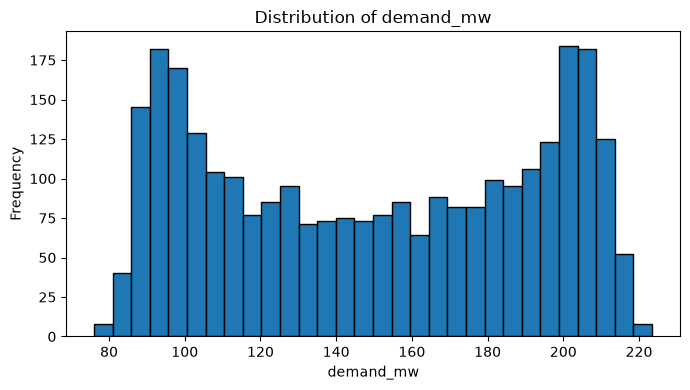

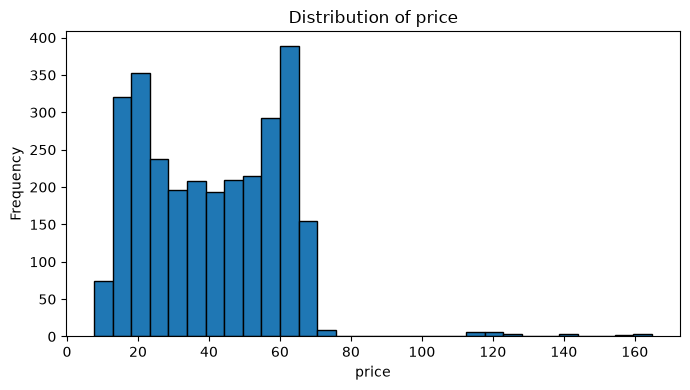

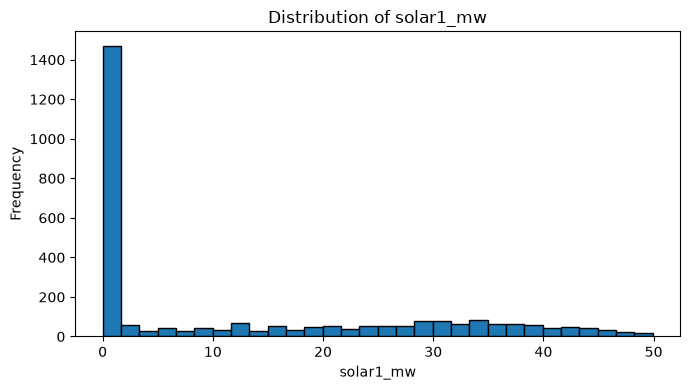

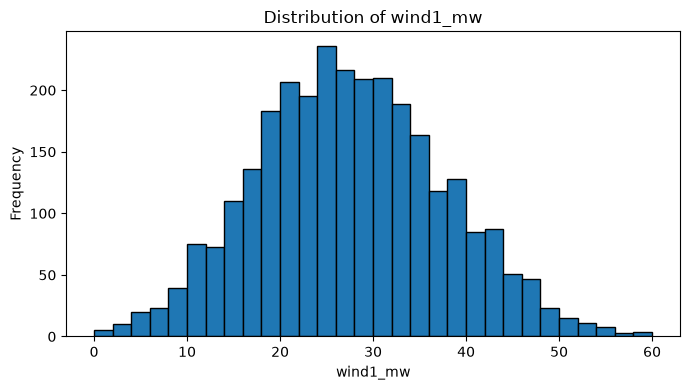

In [12]:
import matplotlib.pyplot as plt

columns = [
    "demand_mw",
    "price",
    "solar1_mw",
    "wind1_mw"
]

for col in columns:
    plt.figure(figsize=(7, 4))
    plt.hist(df[col].dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# Plot variables over time

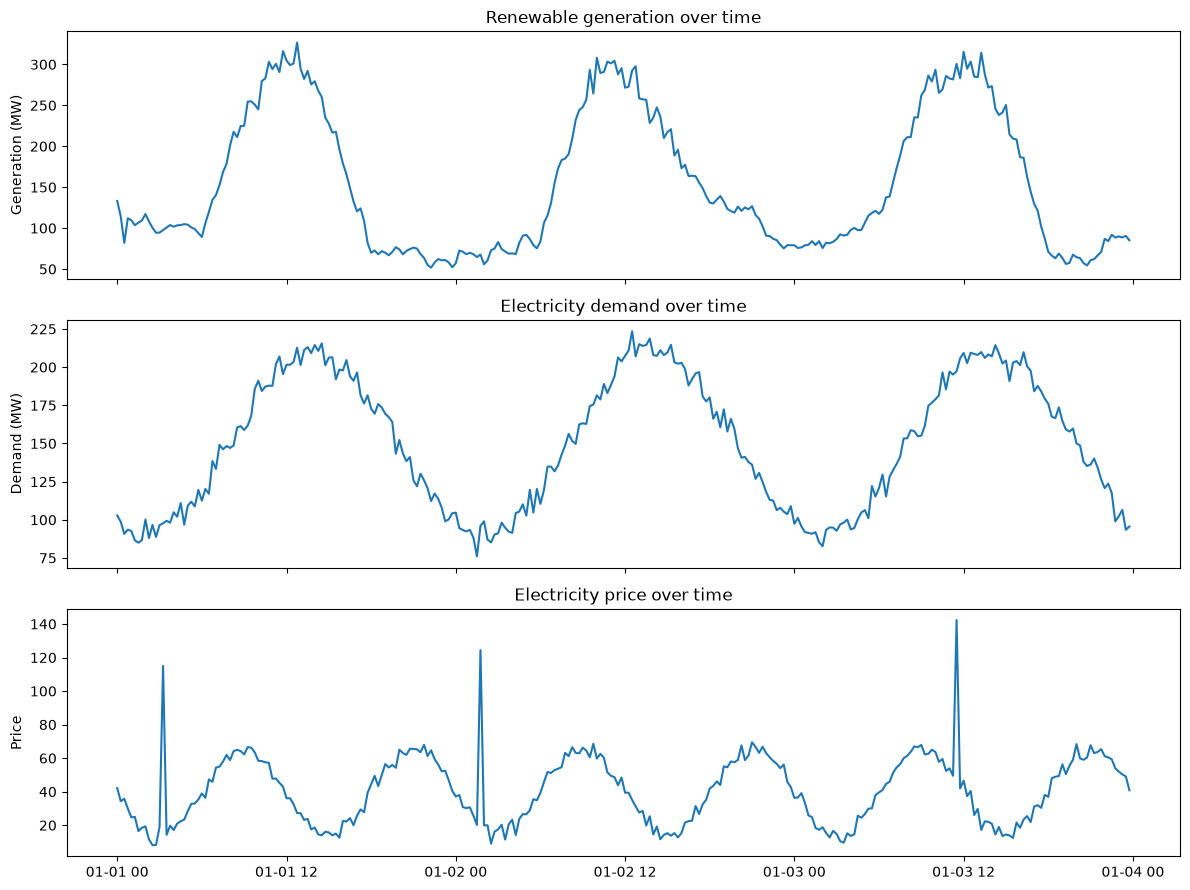

In [13]:

solar_cols = [f"solar{i}_mw" for i in range(1, 6)]
wind_cols = [f"wind{i}_mw" for i in range(1, 4)]

df["solar_total_mw"] = df[solar_cols].sum(axis=1)
df["wind_total_mw"] = df[wind_cols].sum(axis=1)

df["renewable_total_mw"] = (
    df["solar_total_mw"] + df["wind_total_mw"]
)

# Plot the first three days for readability
start = df["time"].min()
sample = df[df["time"] < start + pd.Timedelta(days=3)]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(sample["time"], sample["renewable_total_mw"])
axes[0].set_ylabel("Generation (MW)")
axes[0].set_title("Renewable generation over time")

axes[1].plot(sample["time"], sample["demand_mw"])
axes[1].set_ylabel("Demand (MW)")
axes[1].set_title("Electricity demand over time")

axes[2].plot(sample["time"], sample["price"])
axes[2].set_ylabel("Price")
axes[2].set_title("Electricity price over time")

plt.tight_layout()
plt.show()

In [14]:
hour = df["time"].dt.hour + df["time"].dt.minute / 60
print(hour)

0        0.00
1        0.25
2        0.50
3        0.75
4        1.00
        ...  
2875    22.75
2876    23.00
2877    23.25
2878    23.50
2879    23.75
Name: time, Length: 2880, dtype: float64


# compare pattern by hour

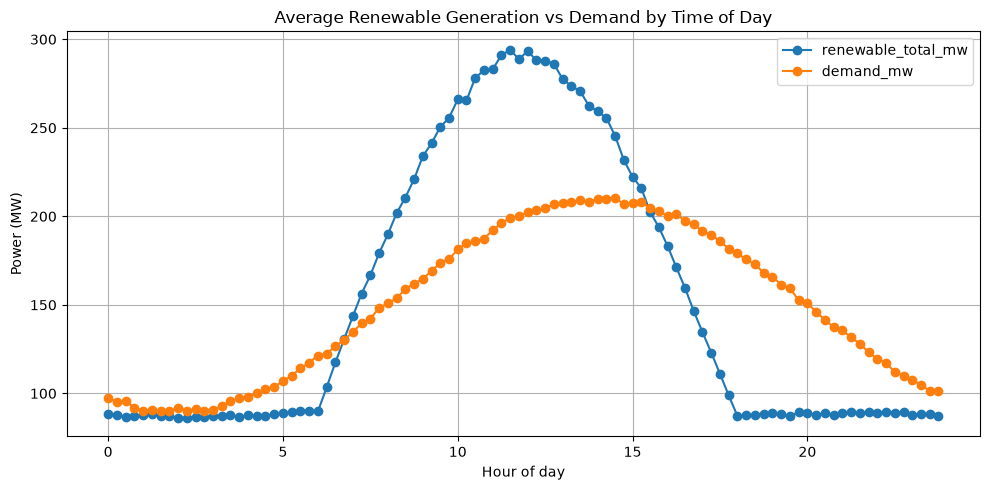

In [15]:

df["hour"] = (
    df["time"].dt.hour + df["time"].dt.minute / 60
)

hourly = df.groupby("hour")[
    ["solar_total_mw", "wind_total_mw",
     "renewable_total_mw", "demand_mw", "price"]
].mean()

hourly[["renewable_total_mw", "demand_mw"]].plot(
    figsize=(10, 5), marker="o"
)
plt.title("Average Renewable Generation vs Demand by Time of Day")
plt.xlabel("Hour of day")
plt.ylabel("Power (MW)")
plt.grid(True)
plt.tight_layout()
plt.show()

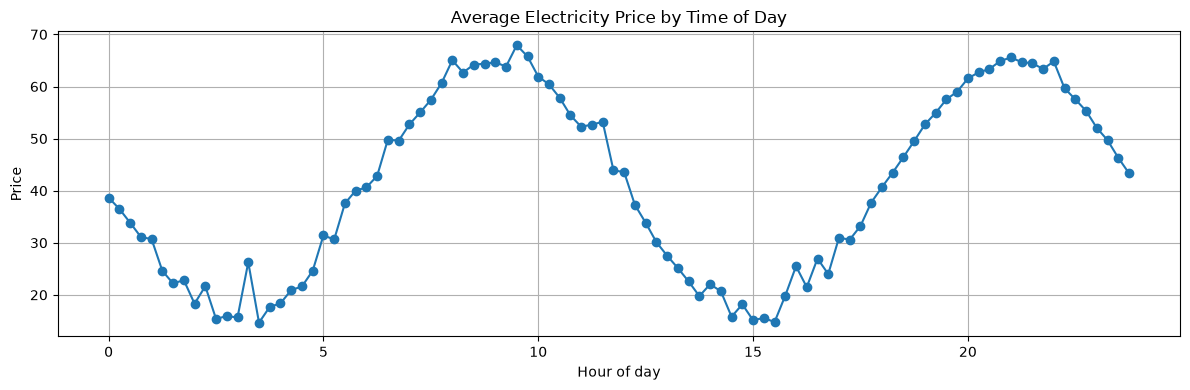

In [16]:
hourly["price"].plot(figsize=(12, 4), marker="o")
plt.title("Average Electricity Price by Time of Day")
plt.xlabel("Hour of day")
plt.ylabel("Price")
plt.grid(True)
plt.tight_layout()
plt.show()

# Check relationship

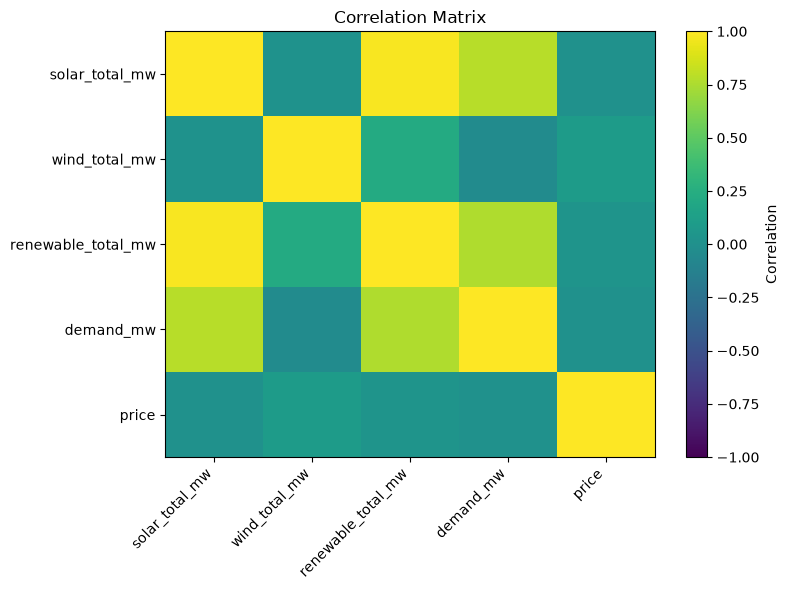

                    solar_total_mw  wind_total_mw  renewable_total_mw  \
solar_total_mw                1.00           0.02                0.98   
wind_total_mw                 0.02           1.00                0.22   
renewable_total_mw            0.98           0.22                1.00   
demand_mw                     0.79          -0.03                0.76   
price                         0.01           0.10                0.03   

                    demand_mw  price  
solar_total_mw           0.79   0.01  
wind_total_mw           -0.03   0.10  
renewable_total_mw       0.76   0.03  
demand_mw                1.00   0.01  
price                    0.01   1.00  


In [17]:

corr_cols = [
    "solar_total_mw",
    "wind_total_mw",
    "renewable_total_mw",
    "demand_mw",
    "price"
]

corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print(corr.round(2))

In [18]:

# Calculate renewable generation
df["renewable_total_mw"] = (
    df["solar_total_mw"] + df["wind_total_mw"]
)

# Positive = surplus; negative = deficit
df["net_power_mw"] = (
    df["renewable_total_mw"] - df["demand_mw"]
)

df["surplus_mw"] = df["net_power_mw"].clip(lower=0)
df["deficit_mw"] = (-df["net_power_mw"]).clip(lower=0)

# Classify each interval
df["energy_status"] = "balanced"
df.loc[df["net_power_mw"] > 0, "energy_status"] = "surplus"
df.loc[df["net_power_mw"] < 0, "energy_status"] = "deficit"

print("\nInterval counts:")
print(df["energy_status"].value_counts())

print("\nAverage surplus (MW):", round(df["surplus_mw"].mean(), 2))
print("Average deficit (MW):", round(df["deficit_mw"].mean(), 2))
print("Maximum surplus (MW):", round(df["surplus_mw"].max(), 2))
print("Maximum deficit (MW):", round(df["deficit_mw"].max(), 2))


Interval counts:
energy_status
deficit    1598
surplus    1282
Name: count, dtype: int64

Average surplus (MW): 22.92
Average deficit (MW): 21.11
Maximum surplus (MW): 148.09
Maximum deficit (MW): 126.26


# DEMAND: smooth shape + noise

In [19]:
demand_shape = 150 + 60 * np.sin((hour - 8) / 24 * 2 * np.pi)
demand_noise = df["demand_mw"] - demand_shape
sigma_d = demand_noise.std()
print("\nDEMAND noise std (sigma):", round(sigma_d, 2), "MW   (we put in 5)")
print("Best possible MAE for ANY model ~ 0.8 x sigma =", round(0.8 * sigma_d, 2))


DEMAND noise std (sigma): 5.02 MW   (we put in 5)
Best possible MAE for ANY model ~ 0.8 x sigma = 4.02


# PRICE: shape + small noise + random spikes

In [20]:
price_shape = 40 + 25 * np.sin((hour - 6) / 24 * 4 * np.pi)
price_resid = df["price"] - price_shape
is_spike = price_resid > 50
print("\nPRICE spikes:", int(is_spike.sum()), "rows =",
      round(100 * is_spike.mean(), 2), "% of all rows")
print("PRICE noise std without spikes:", round(price_resid[~is_spike].std(), 2), "(we put in 3)")


PRICE spikes: 26 rows = 0.9 % of all rows
PRICE noise std without spikes: 3.01 (we put in 3)


# SOLAR: shape x random cloud factor

In [21]:
sun = np.clip(np.sin((hour - 6) / 12 * np.pi), 0, None)
daytime = sun > 0.2                                    # avoid dividing by tiny numbers
cloud_factor = df.loc[daytime, "solar1_mw"] / (50 * sun[daytime])
print("\nSOLAR cloud factor: min", round(cloud_factor.min(), 2),
      "\nmax", round(cloud_factor.max(), 2),
      "\nmean", round(cloud_factor.mean(), 2),
      "\nstd", round(cloud_factor.std(), 3))
print("(uniform 0.6 to 1.0 has mean 0.80 and std 0.115)")


SOLAR cloud factor: min 0.6 
max 1.0 
mean 0.8 
std 0.116
(uniform 0.6 to 1.0 has mean 0.80 and std 0.115)


# WIND: how much does the past tell us?

In [22]:
print("\nWIND autocorrelation  lag 15min:", round(df["wind1_mw"].autocorr(1), 2),
      "| lag 24h:", round(df["wind1_mw"].autocorr(96), 2))


WIND autocorrelation  lag 15min: 0.95 | lag 24h: -0.1


# compare with the model

In [23]:
m = pd.read_csv("forecast_metrics.csv").set_index("signal")
print("\nDemand: noise floor", round(0.8 * sigma_d, 2),
      "| LightGBM MAE", m.loc["demand", "lgbm_MAE"],
      "| naive MAE", m.loc["demand", "naive_MAE"])


Demand: noise floor 4.02 | LightGBM MAE 4.47 | naive MAE 5.88



Saved eda_plots.png


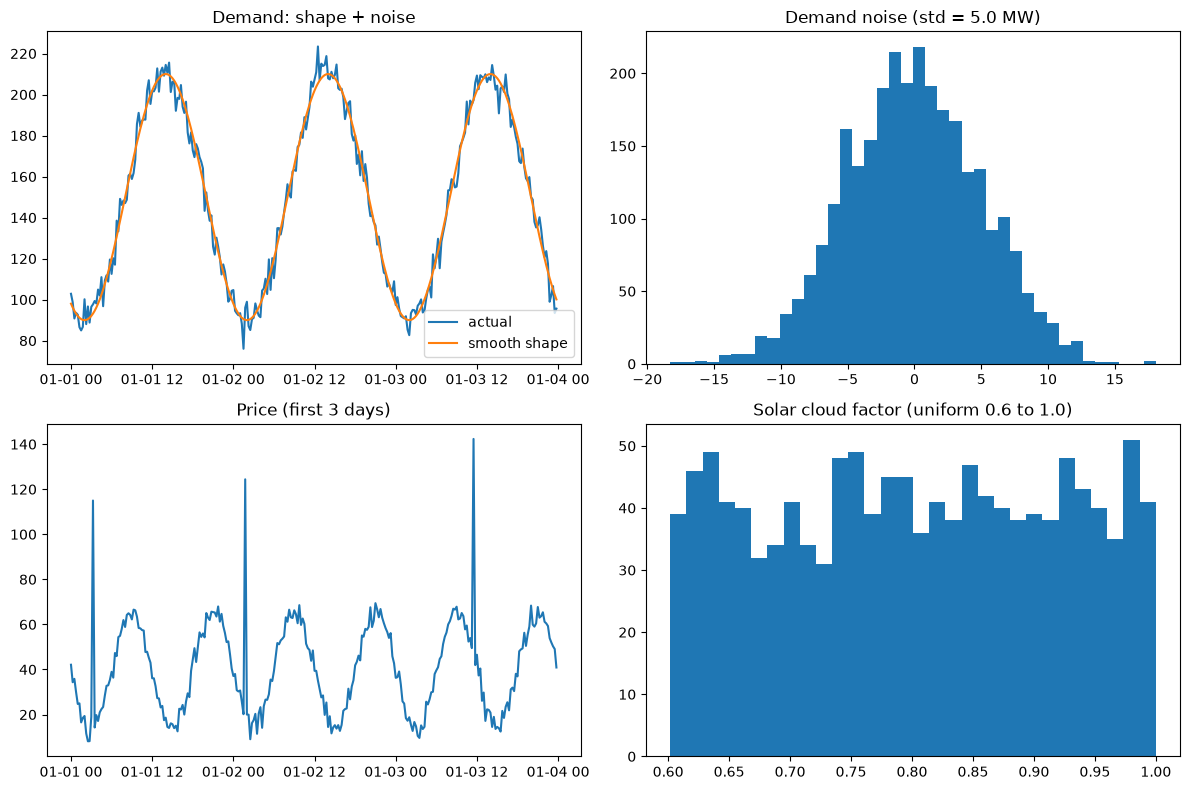

In [24]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
d3 = slice(0, 3 * 96)                                  # first 3 days
ax[0, 0].plot(df["time"][d3], df["demand_mw"][d3], label="actual")
ax[0, 0].plot(df["time"][d3], demand_shape[d3], label="smooth shape")
ax[0, 0].set_title("Demand: shape + noise"); ax[0, 0].legend()
ax[0, 1].hist(demand_noise, bins=40)
ax[0, 1].set_title(f"Demand noise (std = {sigma_d:.1f} MW)")
ax[1, 0].plot(df["time"][d3], df["price"][d3])
ax[1, 0].set_title("Price (first 3 days)")
ax[1, 1].hist(cloud_factor, bins=30)
ax[1, 1].set_title("Solar cloud factor (uniform 0.6 to 1.0)")
plt.tight_layout()
plt.savefig("eda_plots.png", dpi=120)
print("\nSaved eda_plots.png")